In [108]:
import matplotlib.pyplot as plt 
from functools import reduce
import pandas as pd 
import numpy as np 
import os 

In [109]:
my_bucket = os.getenv("WORKSPACE_BUCKET")

In [110]:
from functools import reduce
import pandas as pd

dfs = []

for r in [5, 10, 50, 100, 300]:

    files = []

    for c in [2, 4, 15, 17]:

        f = f"{my_bucket}/data/saige_step02/age_tests/EUR_matched_ratio{r}_single_assoc_chr{c}"

        file = pd.read_csv(f, sep='\t')
        
        file = file[
            (file['AF_Allele2'] > 0.0001) &
            (file['AF_Allele2'] < 0.9999)]

        file = file[['MarkerID', 'BETA', 'p.value']]

        file = file.rename(columns={
            "BETA": f"beta.{r}",
            "p.value": f"p.value.{r}"
        })

        files.append(file)
        
    df = pd.concat(files, axis=0, ignore_index=True)

    dfs.append(df)

merged = reduce(lambda left, right: pd.merge(left, right, on='MarkerID', how='outer'), dfs)

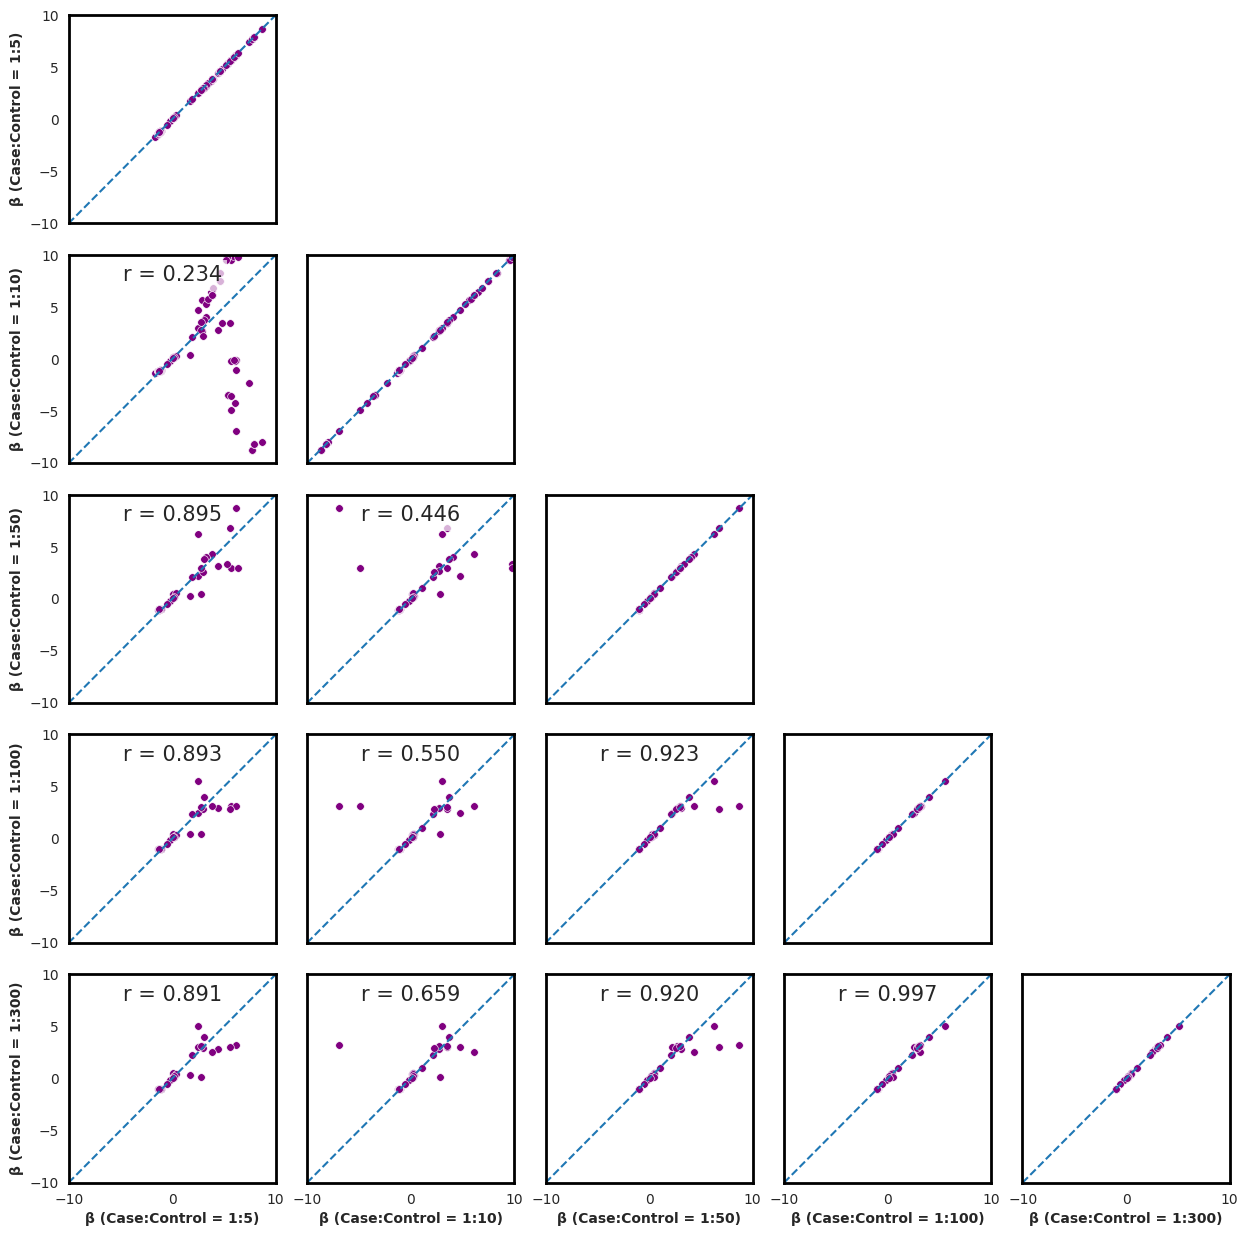

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr


beta_cols = [c for c in merged.columns if c.startswith("beta.")]

rename_dict = {
    "beta.5": "β (Case:Control = 1:5)",
    "beta.10": "β (Case:Control = 1:10)",
    "beta.50": "β (Case:Control = 1:50)",
    "beta.100": "β (Case:Control = 1:100)",
    "beta.300": "β (Case:Control = 1:300)"
}

merged = merged[beta_cols].rename(columns=rename_dict)

beta_cols = merged.columns.tolist()

# symmetric limits around zero
max_abs = np.nanmax(
    np.abs(
        merged[beta_cols].replace([np.inf, -np.inf], np.nan)
    )
)

global_min = -max_abs
global_max = max_abs

g = sns.pairplot(
    merged[beta_cols],
    corner=True,
    diag_kind=None,
    plot_kws={
        's': 30,
        'alpha': 1,
        'color': 'purple'
    }
)

g.fig.subplots_adjust(
    wspace=0.15,   # horizontal spacing
    hspace=0.15    # vertical spacing
)

# add identity line, fix scales, borders, and correlations
for i, row in enumerate(g.axes):
    for j, ax in enumerate(row):
        
        if ax is not None:

            # remove grid
            ax.grid(False)

            # borders
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(2)
                spine.set_edgecolor('black')

            ax.set_xlim(global_min, global_max)
            ax.set_ylim(global_min, global_max)
            
            ax.set_xlabel(ax.get_xlabel(), fontsize=10, fontweight='bold')
            ax.set_ylabel(ax.get_ylabel(), fontsize=10, fontweight='bold')

            # y=x line
            ax.plot(
                [global_min, global_max],
                [global_min, global_max],
                linestyle='--'
            )

            # correlations
            if i > j:

                x = merged[beta_cols[j]].values
                y = merged[beta_cols[i]].values

                mask = np.isfinite(x) & np.isfinite(y)

                if mask.sum() > 1:
                    r, _ = pearsonr(x[mask], y[mask])

                    ax.text(
                        0.5, 0.95,
                        f"r = {r:.3f}",
                        transform=ax.transAxes,
                        ha='center',
                        va='top',
                        fontsize=15,
                        bbox=dict(facecolor='white', 
                                  alpha=0.7, 
                                  edgecolor='none')
                    )
plt.savefig("pairwise_plot.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_274/2324322566.py:126: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for handle in legend.legendHandles:
/tmp/ipykernel_274/2324322566.py:126: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for handle in legend.legendHandles:


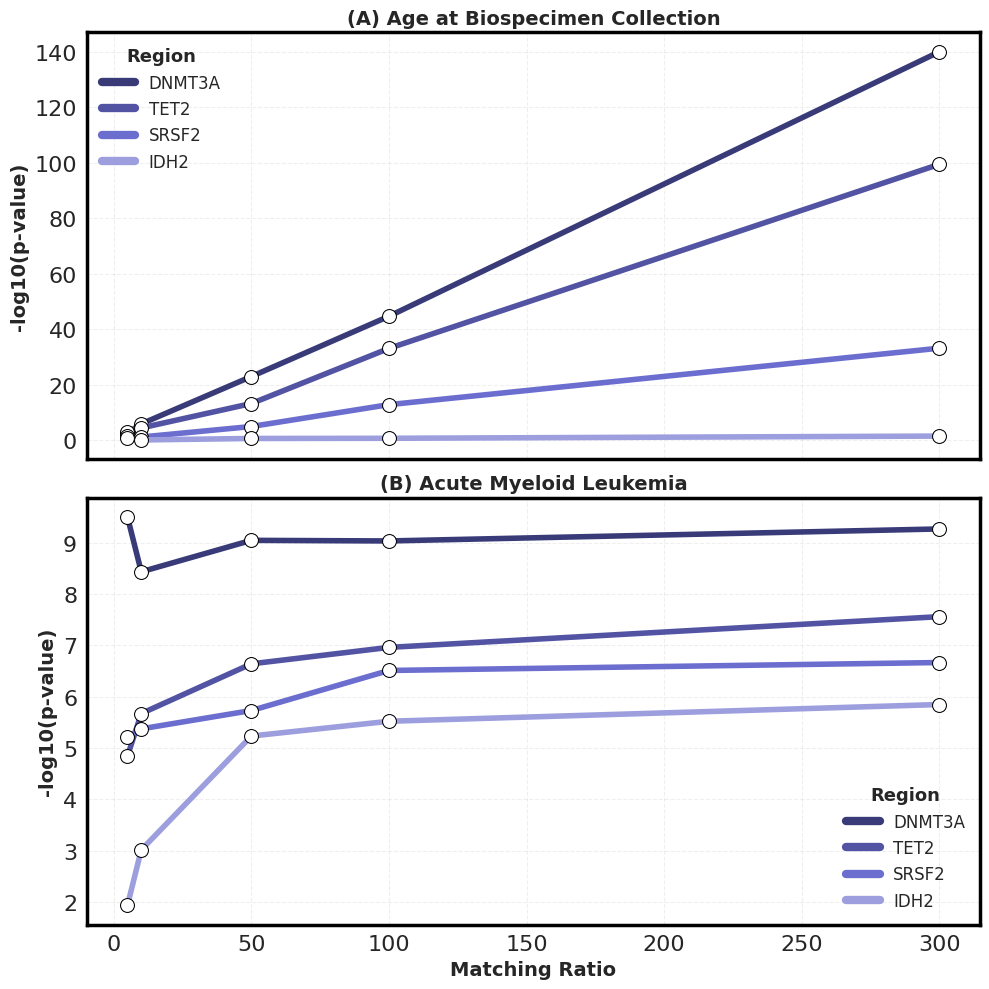

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dfs = []

# -------------------------
# Load Age at Biospecimen
# -------------------------
for chrom in [2, 4, 15, 17]:
    for r in [5, 10, 50, 100, 300]:
        df = pd.read_csv(
            f"{my_bucket}/data/saige_step02/age_tests/EUR_biosample_age_matched_ratio{r}_high_confidence_chr{chrom}",
            sep="\t"
        )
        df = df[df["Group"] == "Cauchy"].copy()
        df["Ratio"] = r
        df["Dataset"] = "(A) Age at Biospecimen Collection"
        dfs.append(df)

# -------------------------
# Load AML dataset
# -------------------------
for chrom in [2, 4, 15, 17]:
    for r in [5, 10, 50, 100, 300]:
        df = pd.read_csv(
            f"{my_bucket}/data/saige_step02/age_tests/EUR_matched_ratio{r}_high_confidence_chr{chrom}",
            sep="\t"
        )
        df = df[df["Group"] == "Cauchy"].copy()
        df["Ratio"] = r
        df["Dataset"] = "(B) Acute Myeloid Leukemia"
        dfs.append(df)

dfs = pd.concat(dfs, ignore_index=True)

# -------------------------
# Gene mapping
# -------------------------
mapping = {
    "ENSG00000119772": "DNMT3A",
    "ENSG00000168769": "TET2",
    "ENSG00000182054": "IDH2",
    "ENSG00000161547": "SRSF2"
}

custom_colors = {
    "DNMT3A": "deepskyblue",
    "TET2": "blue",
    "IDH2": "green",
    "SRSF2": "indigo"
}

dfs["Region"] = dfs["Region"].replace(mapping)
dfs["neg_log10_p"] = -np.log10(dfs["Pvalue"])

summary = dfs.groupby(
    ["Region", "Ratio", "Dataset"]
)["neg_log10_p"].mean().reset_index()

# -------------------------
# Plot
# -------------------------
sns.set_style("whitegrid")

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 10),
    sharex=True
)

datasets = [
    "(A) Age at Biospecimen Collection",
    "(B) Acute Myeloid Leukemia"
]

region_order = ["DNMT3A", "TET2", "SRSF2", "IDH2"]
loc =  ["upper left", "lower right"]
for ax, ds, l in zip(axes, datasets, loc):

    sns.lineplot(
        data=summary[summary["Dataset"] == ds],
        x="Ratio",
        y="neg_log10_p",
        hue="Region",
        marker="o",
        palette='tab20b',
        hue_order=region_order,
        markersize=10,
        linewidth=4,
        markerfacecolor="white",
        markeredgecolor="black",
        ax=ax
    )

    # Titles and labels
    ax.set_title(ds, fontsize=14, fontweight='bold')
    ax.set_xlabel("Matching Ratio", fontsize=14, fontweight='bold')
    ax.set_ylabel("-log10(p-value)", fontsize=14, fontweight='bold')
    ax.tick_params(axis='both', labelsize=16)

    # Grid
    ax.grid(True, linestyle='--', alpha=0.3)

    # Borders (spines)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(2.5)
        spine.set_color("black")

    # Legend
    legend = ax.legend(
        title="Region",
        loc=l,
        frameon=False,
        fontsize=12,
        title_fontsize=13
    )

    legend.get_title().set_fontweight('bold')

    for line in legend.get_lines():
        line.set_linewidth(6)

    for handle in legend.legendHandles:
        handle.set_markersize(11)


plt.tight_layout()
plt.savefig("matching_plot.png", dpi=300, bbox_inches="tight")
plt.show()